# Heart Disease UCI — Exploratory Data Analysis

**Dataset**: UCI Cleveland processed subset (303 samples, 13 features + 1 target)
**Goal**: Understand distributions, class balance, missing values, and feature-target relationships before modeling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

# Where to save plots so MLflow and the report can use them
os.makedirs("notebooks/plots", exist_ok=True)
print("Setup done")

Setup done


In [4]:
cols = ["age","sex","cp","trestbps","chol","fbs","restecg",
        "thalach","exang","oldpeak","slope","ca","thal","target"]

df = pd.read_csv("../data/raw/processed.cleveland.data",
                 names=cols,
                 na_values="?")

print("Shape BEFORE cleaning:", df.shape)
df.head()

Shape BEFORE cleaning: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## 1. Data Quality Check

The raw file has 303 rows. `ca` and `thal` contain `?` for missing values (6 rows total). The target column holds values 0–4 (0 = no disease; 1–4 = disease severity).

In [5]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nRaw target distribution (before binarization):")
print(df["target"].value_counts().sort_index())

Missing values per column:
ca      4
thal    2
dtype: int64

Raw target distribution (before binarization):
target
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


In [6]:
# Binarize: 0 = no disease, 1 = disease (any severity)
df["target"] = (df["target"] > 0).astype(int)

# Drop the 6 rows with missing values (safe: <2% of data)
df = df.dropna().reset_index(drop=True)

print("Shape AFTER cleaning:", df.shape)
print("\nBinarized target distribution:")
print(df["target"].value_counts())
print("\nClass balance (%):")
print((df["target"].value_counts(normalize=True) * 100).round(1))

Shape AFTER cleaning: (297, 14)

Binarized target distribution:
target
0    160
1    137
Name: count, dtype: int64

Class balance (%):
target
0    53.9
1    46.1
Name: proportion, dtype: float64


In [7]:
df.describe().round(2)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00,297.00
mean,54.54,0.68,3.16,131.69,247.35,0.14,1.00,149.60,0.33,1.06,1.60,0.68,4.73,0.46
std,9.05,0.47,0.96,17.76,52.00,0.35,0.99,22.94,0.47,1.17,0.62,0.94,1.94,0.50
min,29.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00,0.00
25%,48.00,0.00,3.00,120.00,211.00,0.00,0.00,133.00,0.00,0.00,1.00,0.00,3.00,0.00
50%,56.00,1.00,3.00,130.00,243.00,0.00,1.00,153.00,0.00,0.80,2.00,0.00,3.00,0.00
75%,61.00,1.00,4.00,140.00,276.00,0.00,2.00,166.00,1.00,1.60,2.00,1.00,7.00,1.00
max,77.00,1.00,4.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,3.00,7.00,1.00


## 2. Class Balance

A balanced dataset means the model isn't biased toward predicting one class. The bar chart below confirms the split is near 54/46.

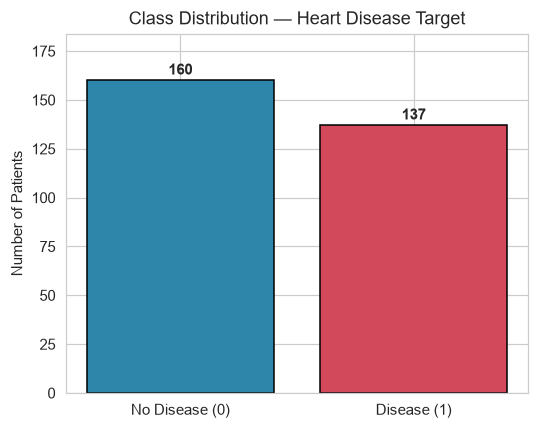

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
counts = df["target"].value_counts().sort_index()
bars = ax.bar(["No Disease (0)", "Disease (1)"], counts.values,
              color=["#2E86AB", "#D1495B"], edgecolor="black")

for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 3, str(val),
            ha="center", fontweight="bold")

ax.set_ylabel("Number of Patients")
ax.set_title("Class Distribution — Heart Disease Target")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.savefig("notebooks/plots/class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Correlation Heatmap

Correlations range from -1 to +1. Values near ±1 indicate strong linear relationships. We look for features that correlate with `target` (candidates for prediction) and pairs of features that correlate with each other (potential redundancy).

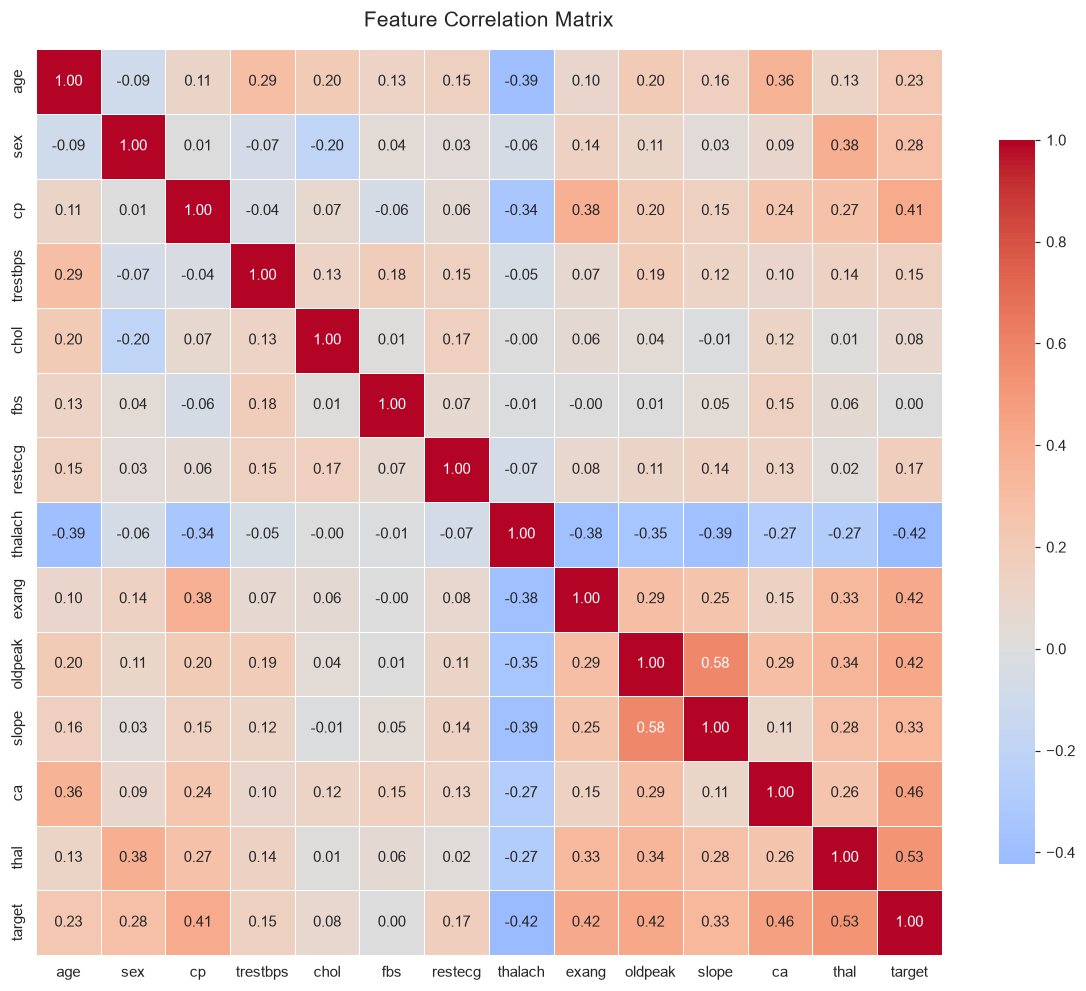

In [9]:
fig, ax = plt.subplots(figsize=(11, 9))
corr = df.corr(numeric_only=True)

sns.heatmap(corr,
            annot=True, fmt=".2f",
            cmap="coolwarm", center=0,
            square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.8},
            ax=ax)
ax.set_title("Feature Correlation Matrix", fontsize=14, pad=15)
plt.tight_layout()
plt.savefig("notebooks/plots/correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Feature Distributions

Histograms show the shape of each numeric feature. Skewed features may benefit from scaling (already planned in the model pipeline). Note that `chol`, `trestbps`, and `oldpeak` are right-skewed.

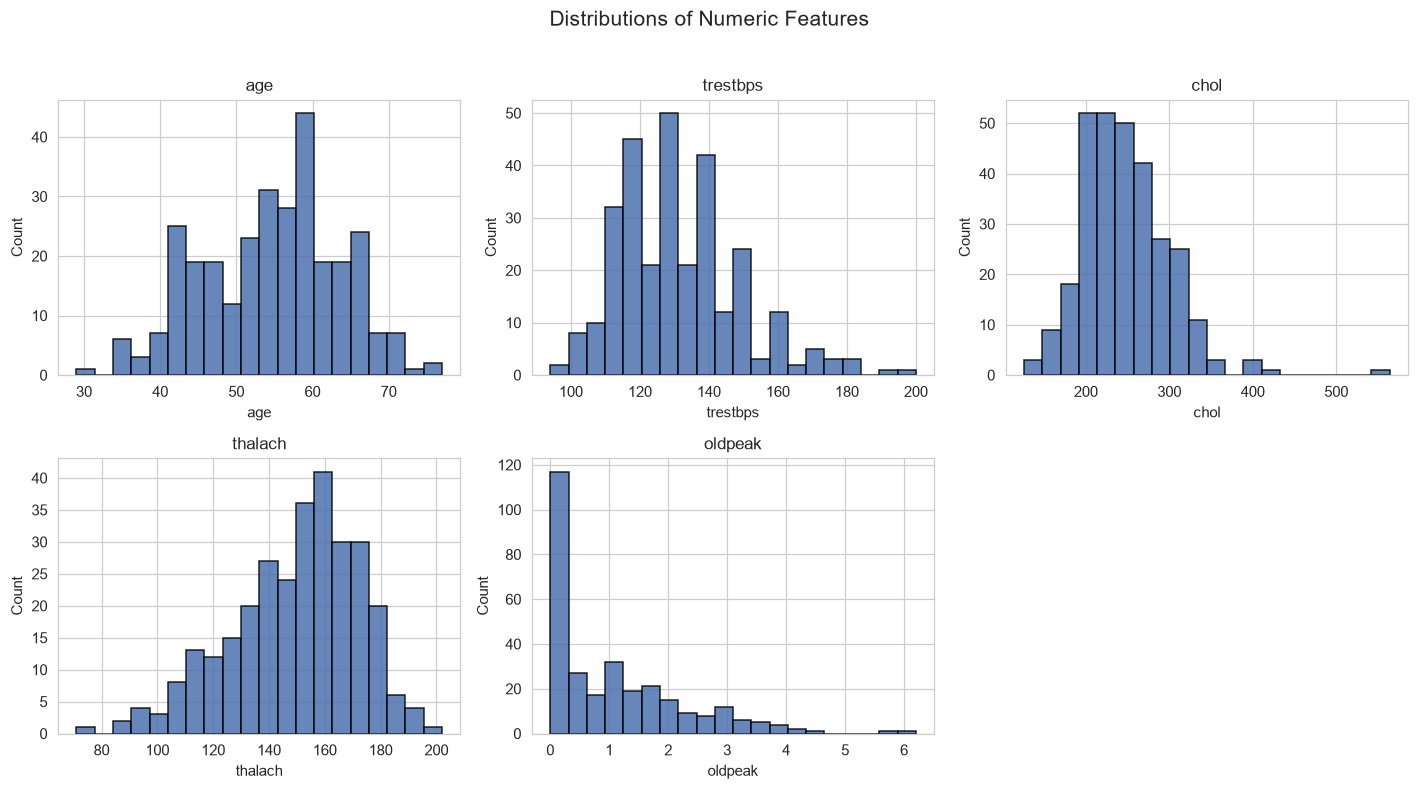

In [10]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].hist(df[col], bins=20, color="#4C72B0", edgecolor="black", alpha=0.85)
    axes[i].set_title(col, fontsize=11)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")

# Hide the unused 6th subplot
axes[-1].axis("off")

plt.suptitle("Distributions of Numeric Features", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("notebooks/plots/histograms.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Key EDA Findings

1. **Size**: 297 usable rows after dropping 6 with missing `ca`/`thal`.
2. **Balance**: 54% no disease vs 46% disease — no class weighting needed.
3. **Missing values**: 2% — dropped, not imputed (negligible impact).
4. **Strongest predictors**: `cp`, `exang`, `oldpeak`, `thalach`, `slope` (all |r| > 0.35 with target).
5. **Skew**: `chol` and `oldpeak` are right-skewed — StandardScaler in the model pipeline will help Logistic Regression converge and treat features uniformly.
6. **Redundancy**: no feature pair is strongly collinear (all pairwise |r| < 0.6), so all 13 features can be kept.